> **Historical analysis:** this notebook retains the earlier temporal-spread response and outputs. For the current lag / plateau-duration / peak-excess metrics, start with [the results synthesis](synthetic_results_synthesis.ipynb) and [predictor validation](synthetic_predictor_validation.ipynb). Earlier `event_duration_change_pct` values here denote cumulative-volume t01–t99, not the current plateau duration.

# Geometry-only predictors of the three collapse responses

Test existing geometric descriptors against **peak-lag change**, **temporal-spread
change**, and **peak-excess change** on the balanced synthetic grid.

Resistance is represented by both $\Lambda_K$ and $R=-\log_{10}\Lambda_K$.
Length fraction $L_f$ and exposure $E$ are tested individually, in all two-component
feature sets, as three separate inputs, and through their existing products,
including the primary predictor $L_f E R$. This distinguishes information in the
components from the constraint imposed by multiplying them together.

The added descriptors reuse existing unit-metric definitions: equivalent length,
equivalent width, elongation, path-length CV and normalized range, effective path
count, dominant width fraction, topology score, and branching density. Metrics
are recalculated over the **matched domain in each parent and child**, including
surviving paths after island collapse. The change features are child minus parent.
Equivalent path width is a length-weighted harmonic mean; effective path count
uses width entropy and is not a cross-section braiding index. Parent geometry is
tested alone; the final set also includes its changes after collapse.

No slope, head, celerity, routing coefficients, forcing duration, or output-derived
quantity is used as a predictor. Geometry is derived before routing. The responses
come from the saved hydrographs; no simulations are rerun.


**Historical supporting analysis:** this notebook retains its saved pre-selection hydraulic setup and, where applicable, earlier spread/quantile metrics. It is not an alpha=0.65 result. Use the current [results synthesis](synthetic_results_synthesis.ipynb) and [predictor validation](synthetic_predictor_validation.ipynb) for the selected setup.


In [5]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'synthetic_experiments').is_dir())
OUT=ROOT/'synthetic_experiments/outputs/full_grid_island/factor_analysis/geometry_predictors'
if not (OUT/'cv_scores.csv').exists():
    raise FileNotFoundError('Run synthetic_experiments/investigations/geometry_predictor_screen.py first.')
scores=pd.read_csv(OUT/'cv_scores.csv')
correlations=pd.read_csv(OUT/'single_variable_correlations.csv')
provenance=json.loads((OUT/'provenance.json').read_text())
RESPONSES={'lag_shift_pct':'Peak-lag change','temporal_spread_change_pct':'Temporal-spread change','peak_excess_change_pct':'Peak-excess change'}
STATES=['simple/full','nested/inner_only','nested/main_island_only','nested/full','crossover/upstream_only','crossover/downstream_only','crossover/full']
NAMES=['Simple: full','Nested: inner','Nested: main island','Nested: full','Crossover: upstream','Crossover: downstream','Crossover: full']
assert set(scores.response)==set(RESPONSES)
assert not scores.duplicated(['state','response','feature_set']).any()
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print(f"{len(scores):,} model/response/collapse combinations; {len(provenance['feature_sets'])} prespecified feature sets; five validation folds each.")
display(pd.DataFrame([{'Feature set':k,'Inputs':', '.join(v) or 'Training-fold mean'} for k,v in provenance['feature_sets'].items()]))


546 model/response/collapse combinations; 26 prespecified feature sets; five validation folds each.


,Feature set,Inputs
0,mean_baseline,Training-fold mean
1,lambda_only,Lambda_matched
2,resistance_only,resistance_log
3,length_fraction_only,length_fraction
4,exposure_only,width_fraction
5,resistance_plus_length,"resistance_log, length_fraction"
6,resistance_plus_exposure,"resistance_log, width_fraction"
7,length_plus_exposure,"length_fraction, width_fraction"
8,three_components,"resistance_log, length_fraction, width_fraction"
9,current_weighted_predictor,resistance_predictor


## Validation: does extra geometry improve held-out predictions?

A fixed, modest gradient-boosted tree model is used for every feature set: 80
iterations, at most seven leaves per tree, minimum leaf size 20, and fixed
regularization. There is no hyperparameter search. Constant features within each
training fold are removed; a constant-only set predicts the training mean.

Five-fold grouped validation is performed **separately for each collapse type**.
Identical complete parent–child geometries, including repeats at different slopes,
are assigned to the same fold. This avoids testing on another slope version of a
geometry already used for training. The folds are identical for every candidate.

$R^2=1$ is perfect prediction; $R^2=0$ matches the overall response-mean benchmark;
negative values are worse. The explicit training-mean baseline can be slightly
negative. MAE and RMSE are in percentage points. The aggregate table weights the
seven collapse types equally; it is not pooled $R^2$. Constant topology/exposure
variables cannot explain within-type variation on their own.

These are exploratory comparisons within the synthetic design, not validation
on unseen real rivers or evidence that a particular metric causes the response.
Choosing a winner from these scores requires a separate validation dataset before
claiming final predictive performance. Omitted slope can still cause different
responses for identical geometric inputs.


response,Peak-lag change,Temporal-spread change,Peak-excess change
feature_set,,,
branching_density_by_length_only,0.333,0.279,0.257
components_plus_geometry,0.856,0.745,0.694
components_plus_geometry_changes,0.858,0.748,0.696
current_weighted_predictor,0.734,0.231,0.190
dominant_width_fraction_only,0.507,0.168,0.144
effective_n_paths_width_only,0.506,0.163,0.134
elongation_only,0.369,0.397,0.333
equivalent_length_only,0.498,0.334,0.364
equivalent_width_only,0.344,0.197,0.152


response,Peak-lag change,Temporal-spread change,Peak-excess change
feature_set,,,
branching_density_by_length_only,5.65,8.88,7.49
components_plus_geometry,1.71,5.31,4.61
components_plus_geometry_changes,1.69,5.27,4.60
current_weighted_predictor,2.69,9.63,7.97
dominant_width_fraction_only,4.58,9.89,8.25
effective_n_paths_width_only,4.56,9.86,8.31
elongation_only,5.25,7.86,6.92
equivalent_length_only,4.45,8.45,6.99
equivalent_width_only,5.57,9.75,8.23


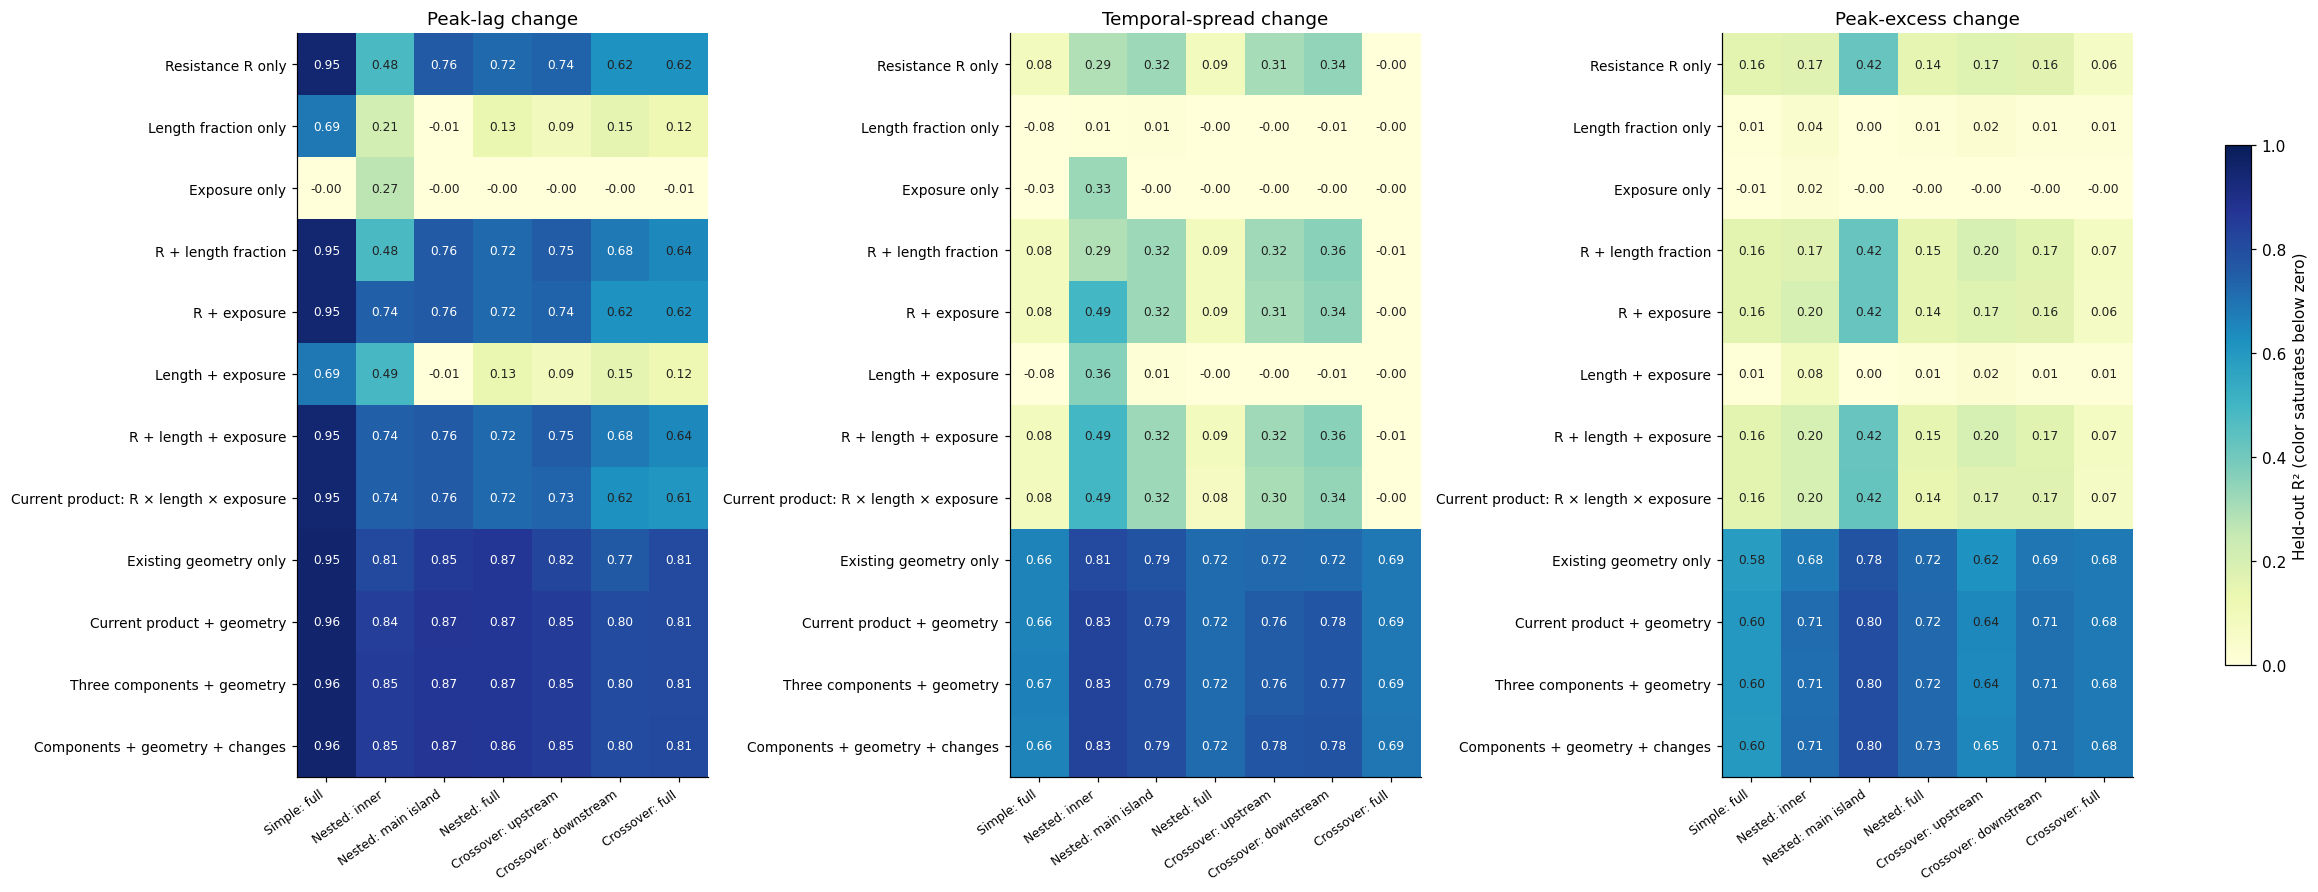

In [6]:
aggregate=scores.groupby(['feature_set','response'])[['r2','mae_pp','rmse_pp']].mean()
display(aggregate['r2'].unstack('response').reindex(columns=RESPONSES).rename(columns=RESPONSES).round(3))
display(aggregate['mae_pp'].unstack('response').reindex(columns=RESPONSES).rename(columns=RESPONSES).round(2))
SHOW={'resistance_only':'Resistance R only','length_fraction_only':'Length fraction only','exposure_only':'Exposure only',
      'resistance_plus_length':'R + length fraction','resistance_plus_exposure':'R + exposure','length_plus_exposure':'Length + exposure',
      'three_components':'R + length + exposure','current_weighted_predictor':'Current product: R × length × exposure',
      'existing_geometry':'Existing geometry only','weighted_predictor_plus_geometry':'Current product + geometry',
      'components_plus_geometry':'Three components + geometry','components_plus_geometry_changes':'Components + geometry + changes'}
fig,axes=plt.subplots(1,3,figsize=(21,8),constrained_layout=True)
for ax,(response,title) in zip(axes,RESPONSES.items()):
    matrix=scores[scores.response.eq(response)].pivot(index='feature_set',columns='state',values='r2').reindex(index=SHOW,columns=STATES)
    # Negative results are annotated exactly; the color scale saturates below zero.
    im=ax.imshow(matrix,cmap='YlGnBu',vmin=0,vmax=1,aspect='auto')
    ax.set_xticks(range(7),NAMES,rotation=35,ha='right',fontsize=8)
    ax.set_yticks(range(len(SHOW)),SHOW.values(),fontsize=9);ax.set_title(title)
    for (i,j),v in np.ndenumerate(matrix.to_numpy()):ax.text(j,i,f'{v:.2f}',ha='center',va='center',fontsize=8,color='white' if v>.65 else '#222')
fig.colorbar(im,ax=axes,label='Held-out R² (color saturates below zero)',shrink=.7)
fig.savefig(OUT/'geometry_prediction_overview.png',dpi=180)
display(fig);plt.close(fig)


## Which individual geometric descriptors show a relationship?

Signed Spearman correlations summarize monotonic association, not prediction.
Positive means larger feature values accompany more positive collapse responses;
this has a different physical meaning for peak excess than for lag or spread.
Gray cells mark constant inputs. The effective path count, dominance, and entropy
family are related; their individual correlations are not independent evidence.


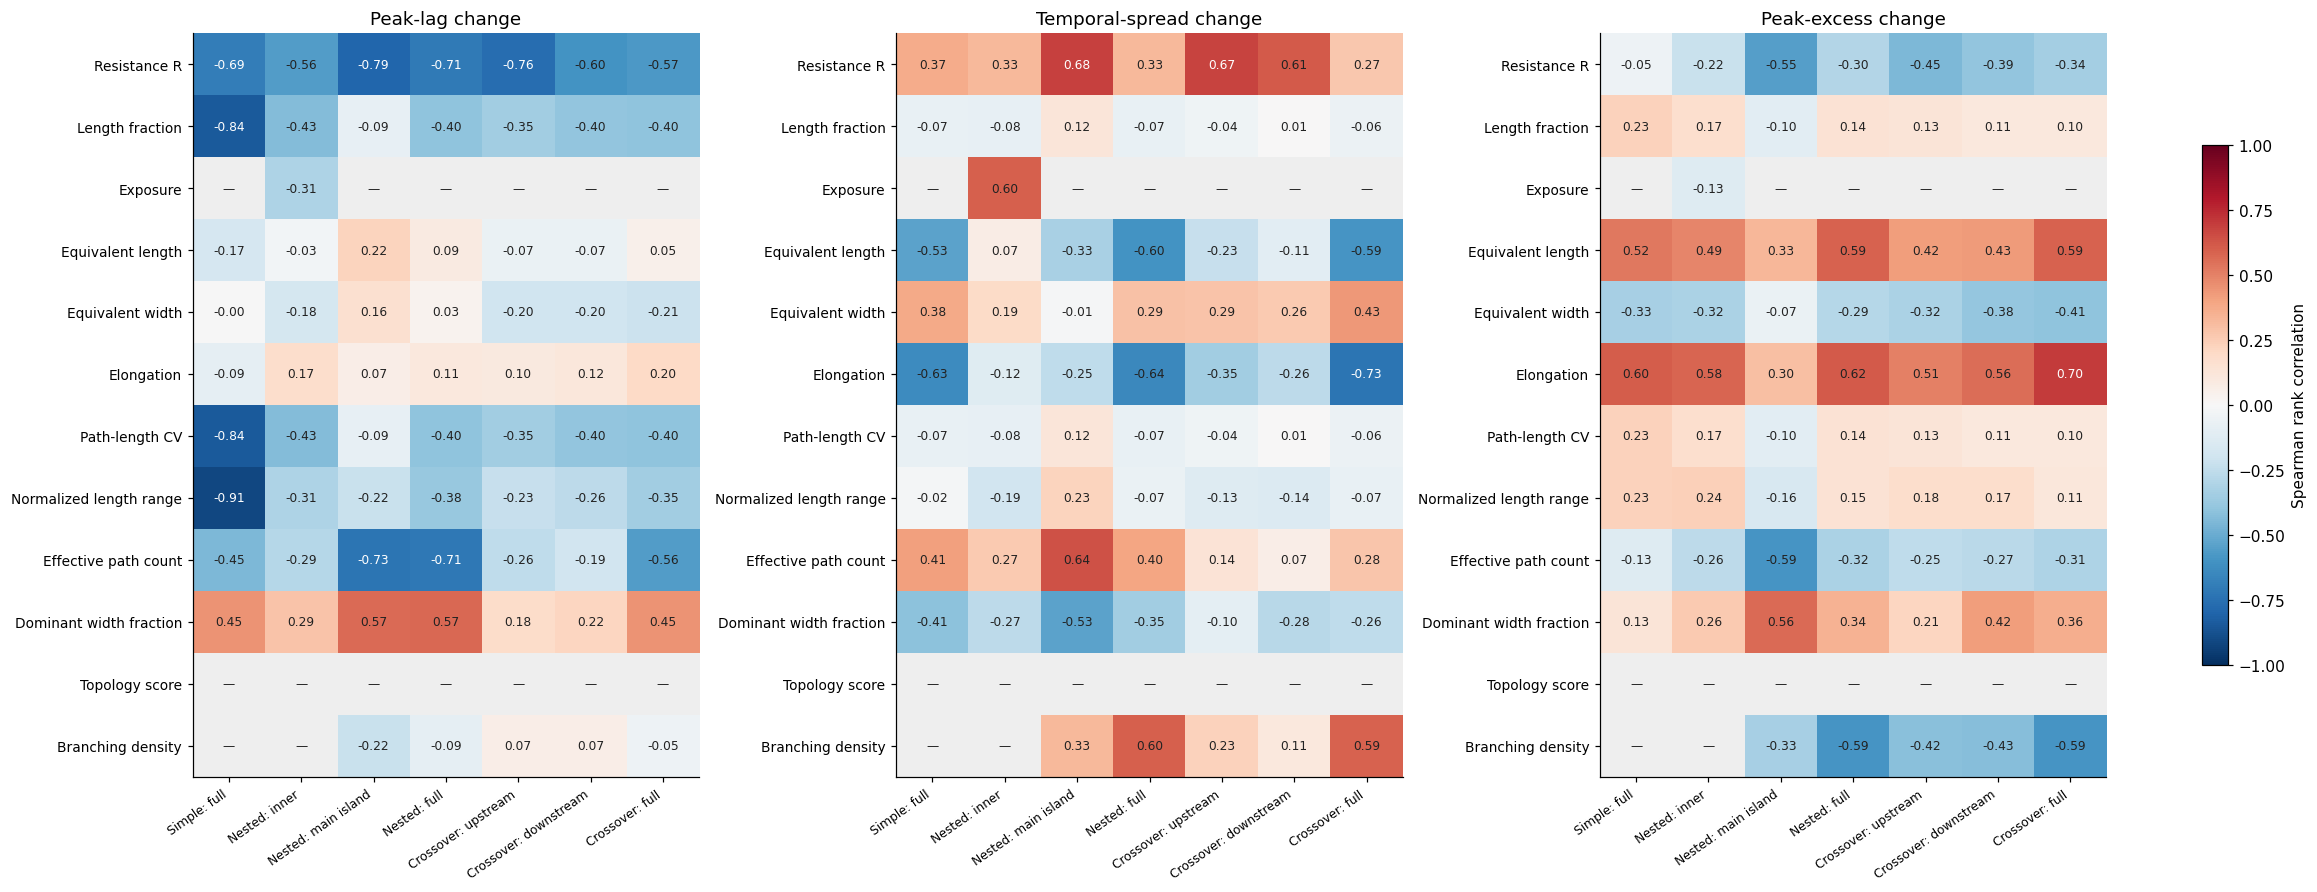

In [7]:
FEATURES={'resistance_log':'Resistance R','length_fraction':'Length fraction','width_fraction':'Exposure',
    'parent_equivalent_length':'Equivalent length','parent_equivalent_width':'Equivalent width','parent_elongation':'Elongation',
    'parent_path_length_cv':'Path-length CV','parent_path_length_range_norm':'Normalized length range',
    'parent_effective_n_paths_width':'Effective path count','parent_dominant_width_fraction':'Dominant width fraction',
    'parent_topologic_complexity_score':'Topology score','parent_branching_density_by_length':'Branching density'}
fig,axes=plt.subplots(1,3,figsize=(21,8),constrained_layout=True)
cmap=plt.get_cmap('RdBu_r').copy();cmap.set_bad('#eeeeee')
for ax,(response,title) in zip(axes,RESPONSES.items()):
    matrix=correlations[correlations.response.eq(response)].pivot(index='feature',columns='state',values='spearman_rho').reindex(index=FEATURES,columns=STATES)
    im=ax.imshow(matrix,cmap=cmap,vmin=-1,vmax=1,aspect='auto')
    ax.set_xticks(range(7),NAMES,rotation=35,ha='right',fontsize=8);ax.set_yticks(range(len(FEATURES)),FEATURES.values(),fontsize=9);ax.set_title(title)
    for (i,j),v in np.ndenumerate(matrix.to_numpy()):
        ax.text(j,i,f'{v:.2f}' if np.isfinite(v) else '—',ha='center',va='center',fontsize=8,color='white' if abs(v)>.65 else '#222')
fig.colorbar(im,ax=axes,label='Spearman rank correlation',shrink=.7)
fig.savefig(OUT/'individual_geometry_correlations.png',dpi=180)
display(fig);plt.close(fig)


## Added value relative to the existing resistance predictor

Compare held-out scores using identical folds. The table reports the change in
$R^2$ and the reduction in MAE after adding the existing geometry to the current
product. Positive values indicate improvement. Geometry-change features are
available in the broader comparison above; these retain which paths survive,
which is particularly relevant to island and partial collapses.


In [8]:
base=scores[scores.feature_set.eq('current_weighted_predictor')].set_index(['state','response'])
aug=scores[scores.feature_set.eq('weighted_predictor_plus_geometry')].set_index(['state','response'])
improvement=pd.DataFrame({'R2_gain':aug.r2-base.r2,'MAE_reduction_pp':base.mae_pp-aug.mae_pp})
display(improvement.round(3))
improvement.to_csv(OUT/'added_geometry_improvement.csv')
# Retain all candidates: this is a screen, not automatic predictor selection.
print('Full feature table, validation folds, held-out predictions and scores:',OUT)


R2_gain  \
state                     response                              
simple/full               lag_shift_pct                 0.008   
                          temporal_spread_change_pct    0.576   
                          peak_excess_change_pct        0.441   
nested/inner_only         lag_shift_pct                 0.099   
                          temporal_spread_change_pct    0.333   
                          peak_excess_change_pct        0.513   
nested/main_island_only   lag_shift_pct                 0.107   
                          temporal_spread_change_pct    0.469   
                          peak_excess_change_pct        0.375   
nested/full               lag_shift_pct                 0.144   
                          temporal_spread_change_pct    0.638   
                          peak_excess_change_pct        0.579   
crossover/upstream_only   lag_shift_pct                 0.114   
                          temporal_spread_change_pct    0.453   
                          peak_excess_change_pct        0.474   
crossover/downstream_only lag_shift_pct                 0.177   
                          temporal_spread_change_pct    0.439   
                          peak_excess_change_pct        0.539   
crossover/full            lag_shift_pct                 0.198   
                          temporal_spread_change_pct    0.687   
                          peak_excess_change_pct        0.615   

                                                      MAE_reduction_pp  
state                     response                                      
simple/full               lag_shift_pct                          0.282  
                          temporal_spread_change_pct             5.114  
                          peak_excess_change_pct                 2.805  
nested/inner_only         lag_shift_pct                          0.567  
                          temporal_spread_change_pct             1.928  
                          peak_excess_change_pct                 2.805  
nested/main_island_only   lag_shift_pct                          0.934  
                          temporal_spread_change_pct             4.225  
                          peak_excess_change_pct                 1.951  
nested/full               lag_shift_pct                          1.104  
                          temporal_spread_change_pct             6.494  
                          peak_excess_change_pct                 4.663  
crossover/upstream_only   lag_shift_pct                          1.204  
                          temporal_spread_change_pct             3.190  
                          peak_excess_change_pct                 2.417  
crossover/downstream_only lag_shift_pct                          1.277  
                          temporal_spread_change_pct             3.093  
                          peak_excess_change_pct                 3.511  
crossover/full            lag_shift_pct                          1.396  
                          temporal_spread_change_pct             6.135  
                          peak_excess_change_pct                 5.341

Full feature table, validation folds, held-out predictions and scores: /Users/6256481/Code/river-hierarchy/synthetic_experiments/outputs/full_grid_island/factor_analysis/geometry_predictors


## Preliminary interpretation

Across the seven collapse types, the current weighted predictor gives mean
held-out R² of **0.734 for lag, 0.231 for spread, and 0.190 for peak excess**.
Adding the existing parent-domain geometry raises these to **0.855, 0.745, and
0.695**, respectively. Keeping the three resistance/length/exposure components
separate gives only **0.751, 0.237, and 0.195**: most of the improvement comes
from additional geometric information, not simply undoing the product.

Elongation alone is more informative for spread and peak excess than the current
product in this screen, but is insufficient by itself. Geometry-only multivariable
sets already perform well; resistance adds a smaller incremental improvement.
Parent–child changes yield a small further average gain, rather than a dramatic
increase. Constant topology and exposure within many collapse types naturally
have no individual predictive skill in this within-type test.

These results establish that useful information is present in our existing
geometric descriptors. They do **not** establish a final scalar equation, nor do
they isolate each descriptor's unique contribution: the inputs are correlated
and the fitted model is nonlinear. The next interpretation step is a small
ablation of the strongest descriptor groups, followed by independent validation.


## Parsimonious predictors and multiplicative axes

**New question:** can a small set of existing variables, or their product, describe
all three responses on a single geometric x-axis?

This is a stricter test than the preceding per-collapse-type fits. Each candidate
now has **one scalar-to-response curve across all collapse types**, separately for
each response. Collapse type is not supplied as an input. Do not directly compare
these scores with the earlier per-type model scores.

Search all products of one, two or three **distinct existing variables**, including
$R=-\log_{10}\Lambda_K$, $L_f$, $E$, raw $\Lambda_K$, the existing composite
$X=L_fER$, and nine parent-domain geometric descriptors. Using $X$ as one factor
allows tests such as $X\times$elongation$\times$dominance. Proportionally identical
products are deduplicated using predictor values only. Products of dimensional
length/width variables are tied to metre units; they are candidate axes, not
universal dimensionless laws. No exponents or hydraulic variables are fitted.

A grouped 25% geometry holdout is reserved from this search. Four-fold grouped CV
on the remaining geometries selects candidates. Repeated geometry at different
slopes stays together. Each scalar uses the same small quadratic spline, with
training-only quantile knots and fixed regularization. This tests a visible curved
relationship rather than forcing a straight line. It is not a fitted power law.

The **shared candidate** maximizes the mean development R² across all three
responses and all seven collapse types. A second shared candidate maximizes the
worst response's mean score. Separate candidates maximize each response's score.
All are selected before the final holdout evaluation. Negative within-type R²
means worse than predicting that type's test-response mean; macro-averaging
prevents between-type differences alone from looking like predictive success.


In [9]:
PRODUCTS=OUT/'products'
search=json.loads((PRODUCTS/'provenance.json').read_text())
ranking=pd.read_csv(PRODUCTS/'product_ranking.csv')
holdout=pd.read_csv(PRODUCTS/'held_out_scores.csv')
ablations=pd.read_csv(PRODUCTS/'ablation_development_scores.csv')
print(f"{search['raw_products']} raw products; {search['unique_products']} distinct scalar candidates.")
display(pd.DataFrame([{'Selection':k,'Product':v} for k,v in search['selected'].items()]))
display(ranking.head(10).round(3))
display(holdout.groupby(['model','response']).r2.mean().unstack().reindex(columns=RESPONSES).rename(columns=RESPONSES).round(3))
display(holdout.groupby(['model','response']).mae_pp.mean().unstack().reindex(columns=RESPONSES).rename(columns=RESPONSES).round(2))


469 raw products; 430 distinct scalar candidates.


,Selection,Product
0,current_product,resistance_predictor
1,shared_product,resistance_log * length_fraction * parent_domi...
2,balanced_shared_product,Lambda_matched * parent_elongation * parent_do...
3,best_for_lag_shift_pct,resistance_predictor * parent_dominant_width_f...
4,best_for_temporal_spread_change_pct,length_fraction * parent_elongation * parent_d...
5,best_for_peak_excess_change_pct,parent_elongation * parent_dominant_width_frac...


,product,lag_shift_pct,temporal_spread_change_pct,peak_excess_change_pct,mean_r2,worst_response_r2,n_factors
0,resistance_log * length_fraction * parent_domi...,0.447,-0.134,-0.106,0.069,-0.134,3
1,resistance_log * resistance_predictor * parent...,0.432,-0.136,-0.100,0.065,-0.136,3
2,resistance_predictor * parent_dominant_width_f...,0.454,-0.158,-0.110,0.062,-0.158,2
3,Lambda_matched * parent_elongation * parent_do...,-0.042,0.138,0.075,0.057,-0.042,3
4,Lambda_matched * parent_elongation,-0.073,0.144,0.087,0.053,-0.073,2
5,resistance_log * width_fraction,0.352,-0.123,-0.079,0.050,-0.123,2
6,resistance_log * resistance_predictor,0.404,-0.165,-0.097,0.047,-0.165,2
7,resistance_log * width_fraction * parent_domin...,0.383,-0.129,-0.114,0.047,-0.129,3
8,resistance_log * parent_effective_n_paths_widt...,0.284,-0.069,-0.088,0.042,-0.088,3
9,resistance_log * width_fraction * resistance_p...,0.407,-0.183,-0.099,0.042,-0.183,3


response,Peak-lag change,Temporal-spread change,Peak-excess change
model,,,
all_geometry_multivariable,0.805,0.548,0.541
balanced_shared_product,-0.093,0.034,0.013
best_for_lag_shift_pct,0.478,-0.154,-0.074
best_for_peak_excess_change_pct,-0.462,0.113,0.143
best_for_temporal_spread_change_pct,-0.465,0.143,0.188
compact_X_elongation_dominance,0.725,0.456,0.488
compact_X_length_dominance,0.748,0.411,0.413
compact_X_length_elongation_dominance,0.763,0.484,0.531
current_product,0.361,-0.237,-0.118


response,Peak-lag change,Temporal-spread change,Peak-excess change
model,,,
all_geometry_multivariable,2.45,6.68,6.10
balanced_shared_product,7.68,9.70,9.34
best_for_lag_shift_pct,4.80,11.38,9.78
best_for_peak_excess_change_pct,8.92,8.90,8.20
best_for_temporal_spread_change_pct,8.96,8.91,8.10
compact_X_elongation_dominance,3.27,7.17,6.52
compact_X_length_dominance,2.87,7.57,6.77
compact_X_length_elongation_dominance,2.88,6.98,6.20
current_product,5.69,11.62,9.88


### Which geometric information is useful?

The addition/removal test uses the same fixed multivariable boosted-tree model
and development folds throughout. **Addition** measures gain over the current
weighted predictor when one descriptor is supplied separately. **Group removal**
measures the loss from omitting related descriptors from the full model. These
are changes in R², not variance-based sensitivity indices.

Correlated inputs can replace one another, so a small individual removal loss
does not establish that a metric is uninformative. The groups are size/proportions
(length, width, elongation), length diversity (CV, normalized range), width balance
(effective path count, dominance), and topology (score, branching density).
The full individual-removal results remain in the exported table.


response,Peak-lag change,Temporal-spread change,Peak-excess change
feature_set,,,
branching_density_by_length,0.108,0.220,0.200
dominant_width_fraction,0.108,0.172,0.132
effective_n_paths_width,0.094,0.158,0.102
elongation,0.053,0.264,0.307
equivalent_length,0.106,0.265,0.275
equivalent_width,0.029,0.106,0.076
path_length_cv,0.094,0.053,0.026
path_length_range_norm,0.121,0.086,0.075
topologic_complexity_score,0.037,0.066,0.008


response,Peak-lag change,Temporal-spread change,Peak-excess change
feature_set,,,
length_diversity,0.004,0.006,0.005
size,0.023,0.136,0.188
topology,0.001,0.002,0.005
width_balance,0.040,0.081,0.110


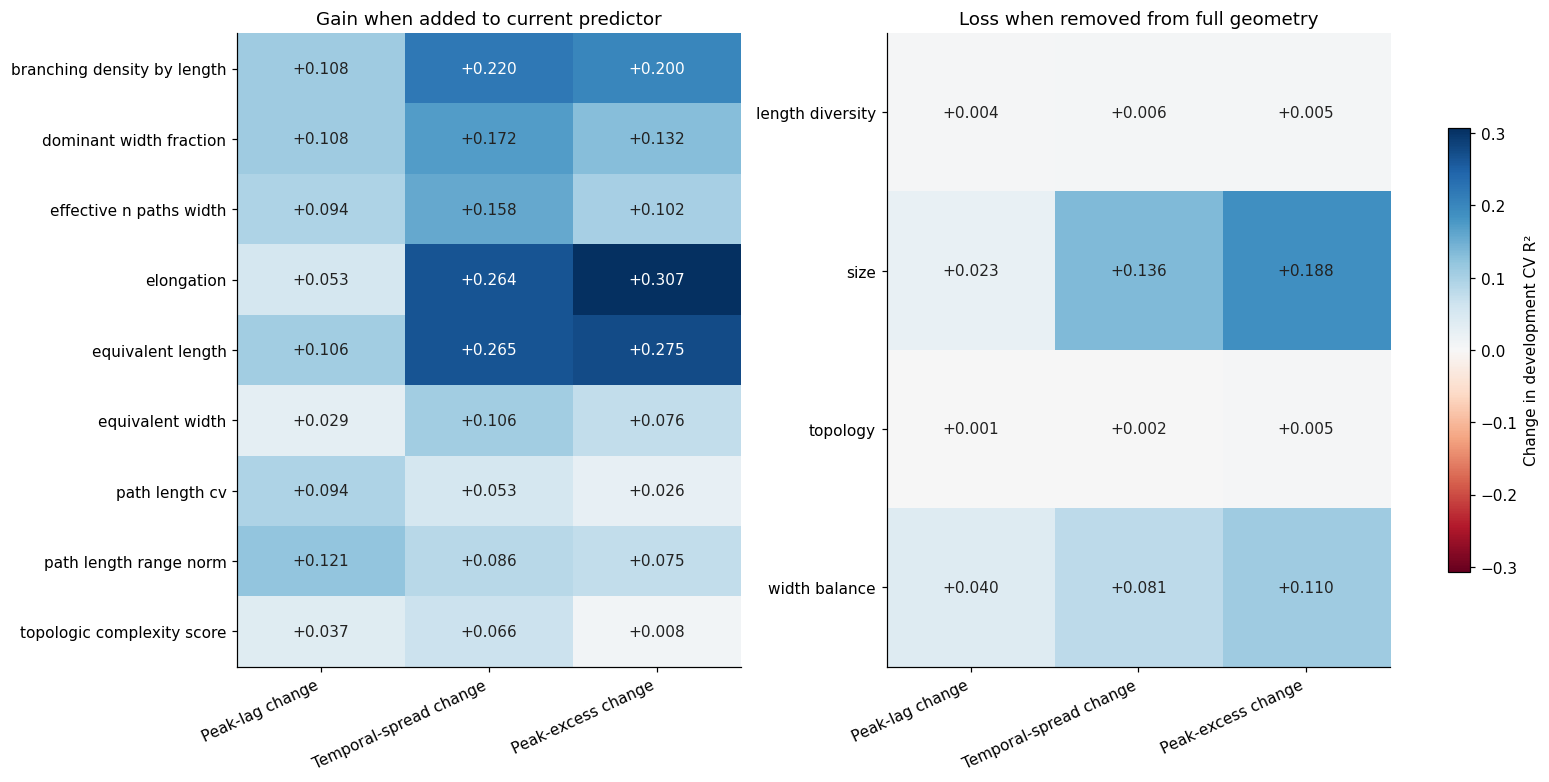

In [10]:
a=ablations.groupby(['feature_set','response']).r2.mean().unstack().reindex(columns=RESPONSES)
addition=a.loc[a.index.str.startswith('add_')].subtract(a.loc['current_product'],axis='columns')
removal=a.loc[a.index.str.startswith('drop_block_')].rsub(a.loc['all_geometry'],axis='columns')
addition.index=addition.index.str.replace('add_parent_','',regex=False)
removal.index=removal.index.str.replace('drop_block_','',regex=False)
display(addition.rename(columns=RESPONSES).round(3));display(removal.rename(columns=RESPONSES).round(3))
fig,axes=plt.subplots(1,2,figsize=(14,7),constrained_layout=True)
limit=max(abs(addition.to_numpy()).max(),abs(removal.to_numpy()).max())
for ax,matrix,title in [(axes[0],addition,'Gain when added to current predictor'),(axes[1],removal,'Loss when removed from full geometry')]:
    im=ax.imshow(matrix,cmap='RdBu',vmin=-limit,vmax=limit,aspect='auto')
    ax.set_xticks(range(3),RESPONSES.values(),rotation=25,ha='right')
    ax.set_yticks(range(len(matrix)),[s.replace('_',' ') for s in matrix.index]);ax.set_title(title)
    for (i,j),v in np.ndenumerate(matrix.to_numpy()):ax.text(j,i,f'{v:+.3f}',ha='center',va='center',color='white' if abs(v)>.65*limit else '#222')
fig.colorbar(im,ax=axes,label='Change in development CV R²',shrink=.7)
fig.savefig(PRODUCTS/'geometry_information_ablation.png',dpi=180)
display(fig);plt.close(fig)


### Does a product give a useful single graph?

The top row uses the **same selected product** for all responses. The bottom row
uses the separately selected product for each response. Points are held-out
geometries; black curves were fitted only to the development data. Colors identify
collapse type, but the fitted curves do not use that label. Scores are macro-average
held-out R² across types. A best-ranked candidate can still be a poor predictor.

Notation: $R$ = log resistance change; $L_f$ = length fraction; $E$ = exposure;
$X=L_fER$; $L,W$ = equivalent length/width; $D$ = dominant width fraction;
$N_e$ = effective path count; $T$ = topology score; $B_d$ = branching density.


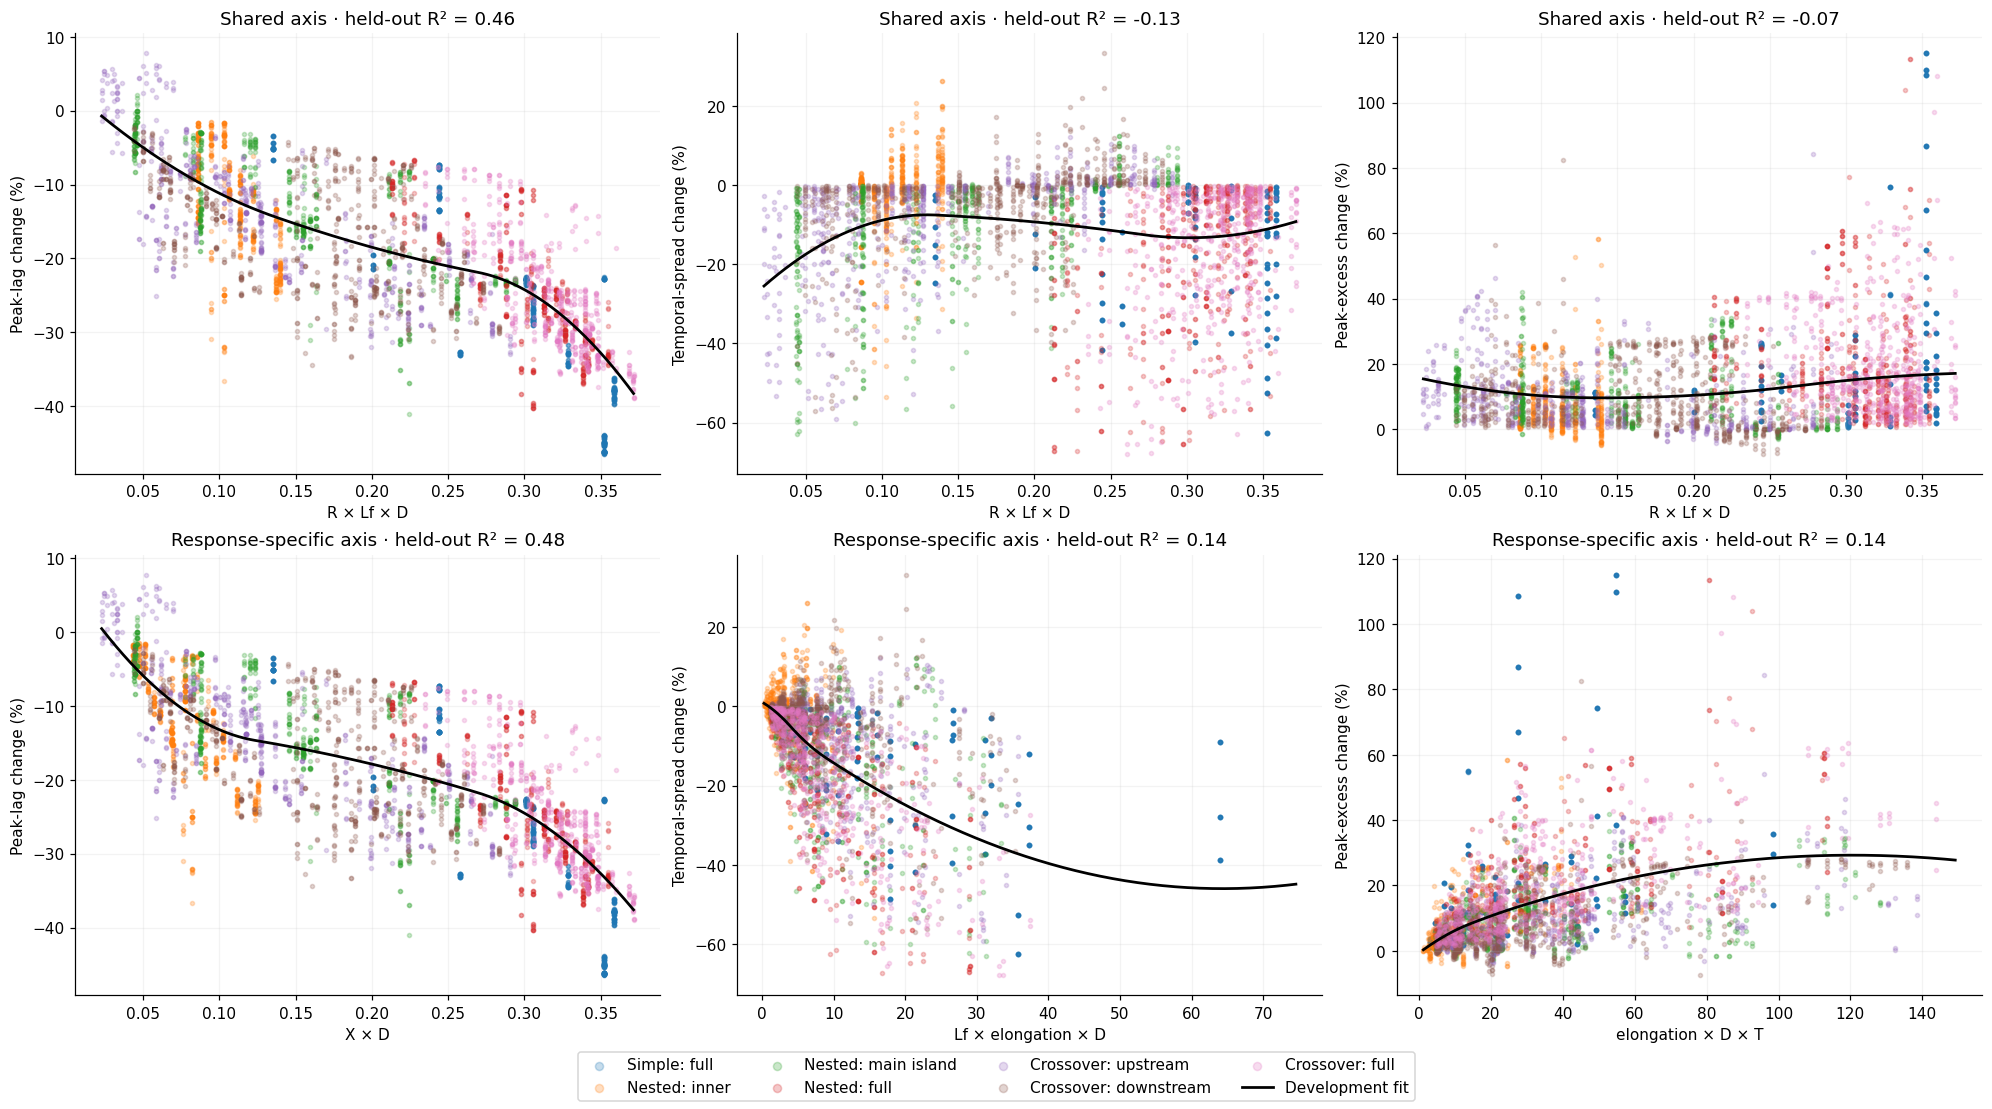

In [11]:
pred=pd.read_parquet(PRODUCTS/'held_out_scalar_predictions.parquet')
curves=pd.read_csv(PRODUCTS/'scalar_curves.csv')
symbols={'resistance_log':'R','length_fraction':'Lf','width_fraction':'E','Lambda_matched':'Λ','resistance_predictor':'X',
    'parent_equivalent_length':'L','parent_equivalent_width':'W','parent_elongation':'elongation','parent_path_length_cv':'length CV',
    'parent_path_length_range_norm':'normalized length range','parent_effective_n_paths_width':'Ne',
    'parent_dominant_width_fraction':'D','parent_topologic_complexity_score':'T','parent_branching_density_by_length':'Bd'}
fig,axes=plt.subplots(2,3,figsize=(18,10),constrained_layout=True)
for col,(response,title) in enumerate(RESPONSES.items()):
    for row,model in enumerate(['shared_product','best_for_'+response]):
        frame=pred[(pred.model==model)&(pred.response==response)]
        curve=curves[(curves.model==model)&(curves.response==response)]
        ax=axes[row,col]
        for state,label in zip(STATES,NAMES):
            part=frame[frame.state.eq(state)]
            ax.scatter(part.x,part.observed,s=7,alpha=.25,label=label,rasterized=True)
        ax.plot(curve.x,curve.predicted,color='black',lw=1.8,label='Development fit')
        score=holdout[(holdout.model==model)&(holdout.response==response)].r2.mean()
        product=search['selected'][model]
        ax.set(xlabel=' × '.join(symbols[v] for v in product.split(' * ')),ylabel=title+' (%)',
               title=('Shared axis' if row==0 else 'Response-specific axis')+f' · held-out R² = {score:.2f}')
        ax.ticklabel_format(axis='x',style='sci',scilimits=(-3,4));ax.grid(alpha=.15)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=4,markerscale=2)
fig.savefig(PRODUCTS/'shared_and_separate_product_axes.png',dpi=180)
display(fig);plt.close(fig)


### A compact common variable set versus one multiplied axis

Based on development-data addition/removal results, also test three compact
sets: $[X,\mathrm{elongation},D]$, $[X,L,D]$, and
$[X,L,\mathrm{elongation},D]$. The same variables are used for all responses,
but each response has its own fitted function. These are **separate inputs**, not
a product. The compact-set choice is made using development CV, with final
performance reported on the reserved geometry groups.


In [12]:
compact_labels=list(search['compact_sets'])
print('Compact set selected on development data:',search['compact_selected_on_development'])
compare=['current_product','shared_product',*compact_labels,'all_geometry_multivariable']
display(holdout[holdout.model.isin(compare)].groupby(['model','response']).r2.mean().unstack().reindex(index=compare,columns=RESPONSES).rename(columns=RESPONSES).round(3))


Compact set selected on development data: compact_X_length_elongation_dominance


response,Peak-lag change,Temporal-spread change,Peak-excess change
model,,,
current_product,0.361,-0.237,-0.118
shared_product,0.458,-0.129,-0.066
compact_X_elongation_dominance,0.725,0.456,0.488
compact_X_length_dominance,0.748,0.411,0.413
compact_X_length_elongation_dominance,0.763,0.484,0.531
all_geometry_multivariable,0.805,0.548,0.541


## What this search supports

**Most useful additions:** size/proportions (particularly elongation and equivalent
length), then width balance. Dominant width fraction adds slightly more than
effective path count in this screen. Length-diversity descriptors add useful lag
information individually, but their unique contribution is small once the other
geometry is available. This does not establish that they are irrelevant outside
the tested grid. Topology alone is not a strong shape predictor here.

**A compact shared input set is viable; a strong universal multiplied axis has
not emerged.** The three-input set $[X,\mathrm{elongation},D]$ achieves held-out
macro R² approximately 0.73 / 0.46 / 0.49 for lag / spread / peak excess. Adding
equivalent length gives approximately 0.76 / 0.48 / 0.53, compared with
0.81 / 0.55 / 0.54 for the larger geometric model.

The best response-specific scalar products achieve approximately 0.48 for lag
and 0.14 for each shape response under the common-curve test. The shared product
is driven by lag performance and performs worse than a within-type mean for
both shape responses. The maximin shared candidate is also weak. These plots
should therefore be treated as a diagnosis of what multiplication loses, not as
recommended predictive equations.

This search used positive products of up to three existing quantities (some
already composite), a fixed small scalar spline, and this particular synthetic
grid. It does not rule out ratios, different exponents, or useful conditional
relationships. Choosing more forms after inspecting this holdout would require
another validation design before claiming improved out-of-sample performance.


## Slope and path-arrangement follow-up

The [new controlled comparison](synthetic_geometry_slope_analysis.ipynb) adds domain reference slope, existing path-length CV, and signed length–width association to the compact geometry set.